# Chapter 11: When You Can't Randomise: Propensity, Weighting and Double ML

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [When You Can't Randomise: Propensity, Weighting and Double ML](https://books.sugiv.fyi/lift/observational.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import observe as O, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


D = O.juno_users()
t, y = D.juno.values, D.retained.values
naive = y[t == 1].mean() - y[t == 0].mean()
truth = (D.y1 - D.y0).mean()
glue_num("naive", 100 * naive)
glue_num("truth", 100 * truth)
glue_num("juno_share", 100 * t.mean())

Here's the finding first. Every quarterly review at Parlo has the same slide: **learners who use Juno are 16 points more likely to still be learning at day 30.** Nobody ever randomised Juno. It's free and optional, and 39% of learners choose to use it. Adjusting carefully for who chooses it, the effect is about **3.5 points**. That's still a real, valuable effect. It's just a fifth of the slide.

Part I could always fall back on a coin flip. This part of the book is for when you can't: the feature already launched to everyone, or it's optional, or randomising would be unfair or impossible. The methods in this chapter can get close to the right answer, but only under an assumption you can't fully test. I'll show the methods, the checks that keep them honest, and the one setting where the assumption is much safer than usual: **evaluating an agent's own decisions.**

> **Note**
>
> The numbers come from `lift/sim/observe.py`. Each learner has a hidden keenness, first-week behaviour that partly reveals it, and both potential outcomes, so we know the truth. Real data never gives you that, which is exactly why the checks later in the chapter matter.

## Draw the graph before you fit the model

Chapter 1 showed why naive comparisons fail: keen learners pick features *and* stay anyway. The fix, without a coin flip, is to compare Juno users with non-users **who looked the same before the choice**. The question is: the same in what?

A causal graph answers that. Each arrow says "this directly affects that":

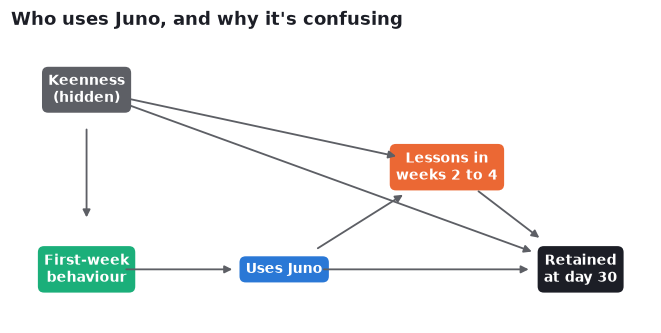

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.set_axis_off()
nodes = {"Keenness\n(hidden)": (0.08, 0.80), "First-week\nbehaviour": (0.08, 0.22),
         "Uses Juno": (0.42, 0.22), "Lessons in\nweeks 2 to 4": (0.70, 0.55), "Retained\nat day 30": (0.93, 0.22)}
colours = {"Keenness\n(hidden)": style.MUTED, "First-week\nbehaviour": style.SERIES[2],
           "Uses Juno": style.SERIES[0], "Lessons in\nweeks 2 to 4": style.SERIES[1],
           "Retained\nat day 30": style.INK}
for name, (x, yy) in nodes.items():
    ax.text(x, yy, name, ha="center", va="center", fontsize=9, color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.45", fc=colours[name], ec="none",
                      linestyle="--" if "hidden" in name else "-"))
edges = [("Keenness\n(hidden)", "First-week\nbehaviour"), ("Keenness\n(hidden)", "Retained\nat day 30"),
         ("Keenness\n(hidden)", "Lessons in\nweeks 2 to 4"), ("First-week\nbehaviour", "Uses Juno"),
         ("Uses Juno", "Lessons in\nweeks 2 to 4"), ("Uses Juno", "Retained\nat day 30"),
         ("Lessons in\nweeks 2 to 4", "Retained\nat day 30")]
for a, b in edges:
    ax.annotate("", xy=nodes[b], xytext=nodes[a],
                arrowprops=dict(arrowstyle="-|>", color=style.MUTED, lw=1.2,
                                shrinkA=26, shrinkB=34, connectionstyle="arc3,rad=0.0"))
ax.set_xlim(-0.05, 1.05); ax.set_ylim(0.05, 0.98)
ax.set_title("Who uses Juno, and why it's confusing", loc="left")
plt.show()

Read it as a set of paths from **Uses Juno** to **Retained**:

- **Juno → Retained** and **Juno → Lessons in weeks 2 to 4 → Retained** are the effect we want. Juno helps directly, and it helps by getting learners to do more lessons.
- **Juno ← First week ← Keenness → Retained** is a *back door*: a path that makes Juno users look better for reasons that have nothing to do with Juno. Learners pick Juno based on how their first week went, and the keenness behind that first week also drives retention.

The rule is short. **Adjust for the things that cause the choice** (first-week behaviour), which blocks the back door. **Don't adjust for the things the choice causes** (lessons in weeks 2 to 4), because that removes part of the effect you're trying to measure.

Here's what happens if you break that second rule. Same data, same regression, one extra control:

In [4]:
base = "retained ~ juno + lessons_wk1 + active_days_wk1 + C(level) + on_ios + evening_learner"


def g_formula(formula, df):
    """Fit a logistic model, then predict everyone with and without Juno."""
    m = smf.logit(formula, df).fit(disp=0)
    return (m.predict(df.assign(juno=1)) - m.predict(df.assign(juno=0))).mean()


pd.Series({"adjust for first week": g_formula(base, D),
           "also adjust for lessons in weeks 2 to 4": g_formula(base + " + lessons_wk2_4", D),
           "truth": truth}).mul(100).round(2).to_frame("Juno's effect (points)")

,Juno's effect (points)
adjust for first week,3.47
also adjust for lessons in weeks 2 to 4,0.86
truth,3.45


In [5]:
glue_num("with_mediator", 100 * g_formula(base + " + lessons_wk2_4", D))

Controlling for the mediator shrinks the effect to 0.9 points. The regression is now asking "does Juno help *among learners who did the same number of later lessons*?", and since getting learners to do more lessons is much of how Juno helps, the answer is "not much". **More controls isn't safer.** Every variable needs a reason, and the graph gives it.

## Four ways to adjust

With the right variables chosen, there are four standard estimators. They make different assumptions about *what* you model, and that matters more than which one is fashionable.

**1. Regression adjustment.** Model retention from Juno use and the covariates, then predict everyone's retention twice, once with Juno and once without, and average the difference. That's the `g_formula` above. It's only as good as the outcome model.

**2. Inverse propensity weighting (IPW).** Model the *choice* instead: each learner's **propensity**, their probability of using Juno given their first week (Rosenbaum and Rubin, 1983). Then reweight. A non-user who looked very likely to use Juno is rare and informative, so they count for a lot. It's the same weighting Chapter 10 used to correct a bandit's dashboard, but there the bandit logged its propensities; here we estimate them.

**3. Doubly robust (AIPW).** Combine both: start from the regression prediction, then correct it with propensity-weighted residuals. It's right if *either* model is right, which is a cheap insurance policy.

**4. Double machine learning (DML).** Doubly robust, with flexible machine-learning models for both pieces, and **cross-fitting**: each learner's predictions come from models trained on the other folds of the data, which stops the models' overfitting from leaking into the estimate (Chernozhukov et al., 2018).

In [6]:
X = O.design_matrix(D)
e_logit = O.logistic_propensity(X, t)
mm = smf.logit(base, D).fit(disp=0)
mu0, mu1 = mm.predict(D.assign(juno=0)).values, mm.predict(D.assign(juno=1)).values
e_ml, m0_ml, m1_ml = O.cross_fit(X, t, y)              # gradient boosting, 5-fold cross-fitting

est = {
    "naive comparison": (naive, np.nan),
    "regression adjustment": (g_formula(base, D), np.nan),
    "inverse propensity weighting": (O.ipw(y, t, e_logit), np.nan),
    "doubly robust (logistic models)": O.aipw(y, t, e_logit, mu0, mu1),
    "double ML (boosted trees, cross-fitted)": O.aipw(y, t, e_ml, m0_ml, m1_ml),
}
tab = pd.DataFrame(est, index=["estimate", "std error"]).T * 100
tab.loc["truth (god view)"] = [100 * truth, np.nan]
tab.round(2)

,estimate,std error
naive comparison,16.06,NaN
regression adjustment,3.47,NaN
inverse propensity weighting,3.45,NaN
doubly robust (logistic models),3.41,0.51
"double ML (boosted trees, cross-fitted)",3.47,0.55
truth (god view),3.45,NaN


In [7]:
glue_num("dml", 100 * est["double ML (boosted trees, cross-fitted)"][0])
glue_num("dml_se", 100 * est["double ML (boosted trees, cross-fitted)"][1])

All four adjusted estimates land near the truth, and the double ML estimate, 3.5 points with a standard error of 0.5, comes with an honest uncertainty from the same formula. Here every method works because the simulation hands them exactly the right covariates and a simple world. In real data, the methods disagree more often, and **when they disagree, that's information**: one of your models is wrong, and the doubly robust estimate is usually the one to trust.

## Check what you can: overlap and balance

Two things *can* be checked, and should be every time.

**Overlap.** Weighting only works if, for every kind of learner, some use Juno and some don't. If the heaviest first-week learners *all* use Juno, there's no one to compare them with, and their weights explode. Plot the propensities:

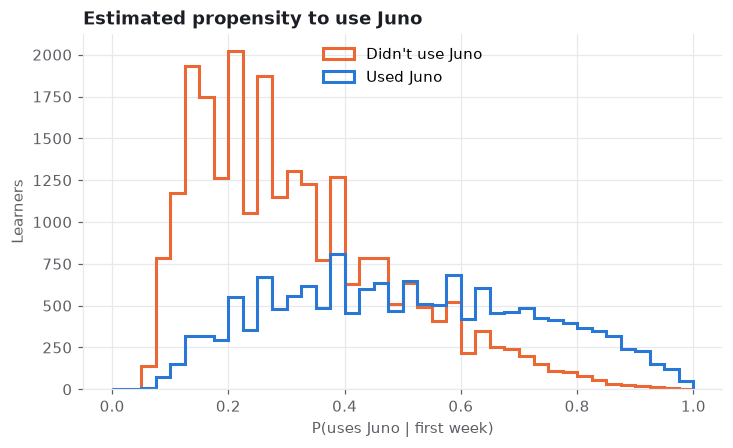

In [8]:
fig, ax = plt.subplots()
bins = np.linspace(0, 1, 41)
ax.hist(e_logit[t == 0], bins=bins, histtype="step", linewidth=2, color=style.SERIES[1], label="Didn't use Juno")
ax.hist(e_logit[t == 1], bins=bins, histtype="step", linewidth=2, color=style.SERIES[0], label="Used Juno")
ax.set(title="Estimated propensity to use Juno", xlabel="P(uses Juno | first week)",
       ylabel="Learners")
ax.legend(loc="upper center")
plt.show()

In [9]:
glue_num("high_e", 100 * (e_logit > 0.95).mean())

There's plenty of overlap in the middle, and a thin right tail: about 0.4% of learners have a propensity above 0.95. Those learners are almost certain to use Juno, so the comparison says little about them. Common practice is to **trim**: drop learners with extreme propensities and say plainly that the estimate covers only the learners where both choices happen. A gentler option, which the double ML code uses, is to **clip** propensities at 0.01 and 0.99: it keeps everyone but stops a handful of weights from exploding.

**Balance.** After weighting, users and non-users should look alike on every covariate. The **standardised mean difference** measures the gap in units of standard deviation; under 0.1 is the usual bar.

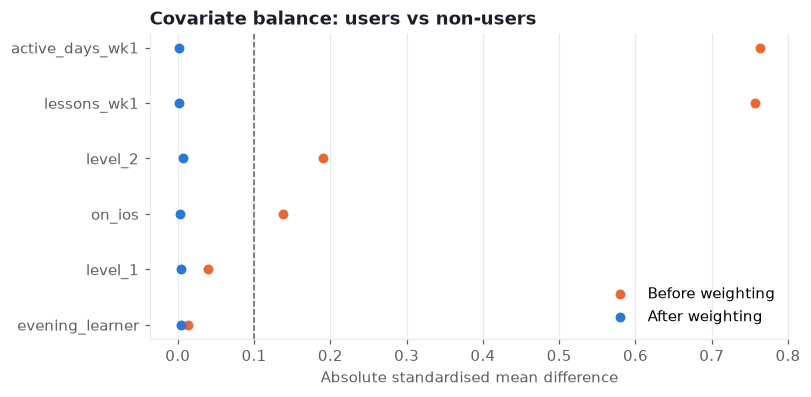

In [10]:
w = np.where(t == 1, 1 / e_logit, 1 / (1 - e_logit))
cols = list(X.columns)
before = [O.smd(X[c].values, t) for c in cols]
after = [O.smd(X[c].values, t, w) for c in cols]
order = np.argsort(np.abs(before))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ypos = np.arange(len(cols))
ax.scatter(np.abs(np.array(before)[order]), ypos, color=style.SERIES[1], s=30, label="Before weighting", zorder=3)
ax.scatter(np.abs(np.array(after)[order]), ypos, color=style.SERIES[0], s=30, label="After weighting", zorder=3)
ax.axvline(0.1, color=style.MUTED, linewidth=1, linestyle="--")
ax.set_yticks(ypos, [cols[i] for i in order])
ax.set(title="Covariate balance: users vs non-users", xlabel="Absolute standardised mean difference")
ax.legend(loc="lower right")
ax.grid(axis="y")
plt.show()

Before weighting, Juno users had far more first-week lessons and active days. After weighting, every covariate is under the 0.1 line. Balance on what you measured is necessary. It isn't sufficient, which brings us to the part you can't check.

## The assumption you can't test

Everything above assumes that, once you know a learner's first week, whether they use Juno has nothing more to do with how keen they are. Formally: **no unmeasured confounding**. Real data never lets you verify it. A simulator does, so here's what happens as the assumption breaks: learners also choose Juno based on keenness their first week didn't reveal.

In [11]:
rows = []
for hidden in [0.0, 0.5, 1.0]:
    Dh = O.juno_users(hidden=hidden)
    th, yh = Dh.juno.values, Dh.retained.values
    eh = O.logistic_propensity(O.design_matrix(Dh), th)
    mh = smf.logit(base, Dh).fit(disp=0)
    est_h, _ = O.aipw(yh, th, eh, mh.predict(Dh.assign(juno=0)).values, mh.predict(Dh.assign(juno=1)).values)
    rows.append({"hidden keenness: odds of using Juno per SD of unseen keenness": f"x{np.exp(hidden):.1f}",
                 "doubly robust estimate (points)": 100 * est_h,
                 "truth (points)": 100 * (Dh.y1 - Dh.y0).mean()})
sens = pd.DataFrame(rows).set_index("hidden keenness: odds of using Juno per SD of unseen keenness").round(1)
sens

,doubly robust estimate (points),truth (points)
hidden keenness: odds of using Juno per SD of unseen keenness,,
x1.0,3.4,3.4
x1.6,7.9,3.4
x2.7,11.7,3.4


In [12]:
glue_num("sens_mid", sens.iloc[1, 0])
glue_num("sens_hi", sens.iloc[2, 0])

If unseen keenness raises the odds of using Juno by 1.6 times per standard deviation, a modest amount, the estimate rises to 7.9 points. At 2.7 times it's 11.7. Balance checks would pass in every row, because they can only see what you measured.

This is a **sensitivity analysis**, and it's the honest way to report an observational result: "Juno adds about 3.5 points if first-week behaviour captures why people choose it; if there's hidden motivation of this size, the true effect could be smaller still." Then ask the product question: *is there something about keen learners that our first-week data misses?* For Parlo, probably yes (people studying for an exam, say). That's why this estimate should be confirmed with an experiment when one becomes possible. Chapter 13 shows a clever way to get one: randomise the *encouragement* to use Juno, even if you can't randomise Juno itself.

## Juno's dictionary tool: the friendliest observational data there is

Now the agent version. Juno has a dictionary tool it can call mid-lesson to look up a word. Juno's team wants to know whether the tool helps learners complete lessons. The logs say the opposite:

In [13]:
Tl = O.dictionary_tool()
Tl.groupby(Tl.tool_called.map({0: "no lookup", 1: "Juno looked a word up"})) \
  .agg(lessons=("completed", "size"), completion=("completed", "mean"), difficulty=("difficulty", "mean"))

,lessons,completion,difficulty
tool_called,,,
Juno looked a word up,19182,0.585,0.565
no lookup,10818,0.690,0.385


In [14]:
tl_naive = Tl.completed[Tl.tool_called == 1].mean() - Tl.completed[Tl.tool_called == 0].mean()
tl_truth = (Tl.y1 - Tl.y0).mean()
glue_num("tl_naive", 100 * tl_naive)
glue_num("tl_drop", -100 * tl_naive)
glue_num("tl_truth", 100 * tl_truth)

Lessons with a lookup complete 10 points *less* often. That's the same selection problem again: Juno looks words up in hard lessons, and hard lessons are completed less often.

But this time there's a crucial difference. **The thing making the choice is code.** Juno decides whether to call the tool from inputs that are all in the log: lesson difficulty, the number of rare words, the task type. There's no hidden keenness, no private motivation. If you log what the agent saw, you've logged every confounder. And because Juno samples its tool decisions with some temperature, the team can log the *probability* it assigned to calling the tool, which is the propensity itself, no model needed:

In [15]:
yt, tt, et = Tl.completed.values, Tl.tool_called.values, Tl.p_call_logged.values
Xt = pd.get_dummies(Tl[["difficulty", "rare_words", "task"]], columns=["task"], dtype=float)
e_fit, m0_t, m1_t = O.cross_fit(Xt, tt, yt)
dr_logged = O.aipw(yt, tt, np.clip(et, 0.01, 0.99), m0_t, m1_t)
pd.Series({"naive": tl_naive,
           "IPW with logged probabilities": O.ipw(yt, tt, et),
           "doubly robust, logged probabilities": dr_logged[0],
           "double ML, estimated propensities": O.aipw(yt, tt, e_fit, m0_t, m1_t)[0],
           "truth": tl_truth}).mul(100).round(1).to_frame("tool's effect on completion (points)")

,tool's effect on completion (points)
naive,-10.5
IPW with logged probabilities,4.2
"doubly robust, logged probabilities",4.6
"double ML, estimated propensities",4.7
truth,5.3


In [16]:
glue_num("tl_dr", 100 * dr_logged[0])
glue_num("tl_se", 100 * dr_logged[1])

The sign flips. The doubly robust estimate is +4.6 points with a standard error of 0.7, within about one standard error of the true +5.3. The tool helps; it just gets used where lessons are hardest.

This is the best news in the chapter for agent teams. **An agent's decisions are an observational study you designed yourself.** Three habits make it nearly as good as an experiment:

- **Log the inputs to every decision**: the features, the retrieved context, the prompt version. Those are your confounders, and you have all of them.
- **Log the decision probability** where there is one: a router's softmax, a sampled tool choice, a bandit's propensity (Chapters 9 and 10).
- **Keep a little randomness**: a small exploration rate guarantees overlap, so every kind of lesson sometimes gets each choice.

Where those break, for example when the agent's choice depends on something not logged, like a cached memory or a human reviewer's judgement, you're back to the hidden-confounding problem and need the sensitivity analysis.

## Which method when

| Situation | Method | Main assumption |
|---|---|---|
| You can randomise | An experiment (Part I) | None that matter |
| Agent or system decisions, inputs logged | IPW or doubly robust with logged propensities | Everything the decision used is in the log |
| People choose, rich pre-choice data | Double ML, with overlap, balance and sensitivity checks | No hidden reason for the choice |
| A policy change at a date or threshold | Difference-in-differences, regression discontinuity (Chapter 12) | Trends or the threshold behave |
| Something randomly nudges the choice | Instrumental variables (Chapter 13) | The nudge affects outcomes only through the choice |

> **In the wild**
>
> In 1986, Robert LaLonde took a job-training programme that had been run as a randomised experiment and asked whether the standard non-experimental methods of the day, applied to the same people with a comparison group drawn from surveys, would recover the experimental answer (LaLonde, 1986). Mostly, they didn't, and they disagreed with each other. Dehejia and Wahba (Dehejia and Wahba, 1999) later showed that propensity score methods with careful overlap checks got much closer. Both lessons stand: adjustment can work, and it can fail badly when the comparison group doesn't overlap.

## Pitfalls

- **Controlling for everything.** Variables affected by the treatment (later lessons, engagement after the choice) remove part of the effect. Draw the graph first.
- **Ignoring overlap.** If some learners always or never choose the feature, the estimate for them is extrapolation. Trim and say so.
- **Treating balance as proof.** Balance covers measured covariates only. Report a sensitivity analysis.
- **Trusting one estimator.** Run regression, IPW and doubly robust. If they disagree, find out why before reporting any of them.
- **Not logging the agent's inputs.** The cheapest causal inference you'll ever do is the one where you logged everything the decision depended on.

## Exercises

1. **Wrong outcome model.** Drop `active_days_wk1` from the regression formula but keep it in the propensity model. What happens to regression adjustment, IPW and the doubly robust estimate? Which one survives?
2. **Effect on the treated.** The chapter estimates the average effect for everyone. Compute the average effect for learners who actually used Juno (the god view has it as `(y1 - y0)[juno == 1]`). Adapt the IPW weights to estimate it.
3. **No temperature.** Make Juno's tool decision deterministic: call it whenever `p_call_logged > 0.5`. What happens to overlap and to IPW with logged probabilities? What does that say about exploration?
4. **Your own sensitivity table.** Pick an observational claim from your own product. What hidden reason for the choice might exist? How strong would it need to be to erase the effect?

## Further reading

Facure (Facure, 2022) covers propensity scores, doubly robust estimation and double ML with clear Python examples. Wager (Wager, 2026) (chapters on unconfoundedness and doubly robust methods) gives the theory, including why cross-fitting works. Chernozhukov and colleagues (Chernozhukov et al., 2018) introduced double machine learning.